# 3D-локалізація за допомогою 2,5D (RGBD) камери

За картою глибини будуємо тривимірний бокс навколо обличчя.

### Підготовка середовища

Імпортуємо бібліотеки, підключаємо дані та навчені ваги. Задаємо параметри камери `CAMERA_CONFIG`.


In [1]:
from pathlib import Path
import contextlib,io,json,math,time,zipfile
import cv2,numpy as np,pandas as pd,torch
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import display,Image
OUT = Path("/kaggle/working/tmfd_face_3d")
OUT.mkdir(parents=True,exist_ok=True)
CAMERA_CONFIG = {
    "model": "pinhole_on_processed_tmfd_frames",
    "calibration_status": "assumed_nominal_fov_not_measured",
    "width": 640,
    "height": 480,
    "fx": 554.2562584220408,
    "fy": 520.6002444850203,
    "cx": 319.5,
    "cy": 239.5,
    "depth_scale_m": 0.001,
    "hfov_deg_assumed": 60,
    "vfov_deg_assumed": 49.5
}
camera_path = OUT/"camera_assumed.json"
camera_path.write_text(json.dumps(CAMERA_CONFIG,indent=2),encoding="utf-8")
import kagglehub
archive_path = Path(kagglehub.dataset_download("silenceo0/tmfd-dataset-face"))
checkpoints = list(Path("/kaggle/input").rglob("spatial_resnet18.pt"))
assert len(checkpoints)==1, "Attach trained silenceo0/tmfd-face-spatial-v1 output"
checkpoint_path = checkpoints[0]
test_ids = pd.read_csv(checkpoint_path.parent/"test_ids.csv").id.astype(str).tolist()
print("Середовище:", "torch", torch.__version__, "· CUDA:", torch.cuda.is_available())
print("Камера:", CAMERA_CONFIG["calibration_status"], "· Тестових кадрів:", len(test_ids))


Середовище: torch 2.11.0+cpu · CUDA: False
Камера: assumed_nominal_fov_not_measured · Тестових кадрів: 239


### Модель локалізації

Визначаємо модель пошуку центра обличчя та декодування параметрів рамки.

In [2]:
import cv2
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
from torchvision import models

class SpatialFaceNet(nn.Module):
    def __init__(self,pretrained=True):
        super().__init__()
        backbone = models.resnet18(weights="DEFAULT" if pretrained else None)
        first = backbone.conv1
        conv = nn.Conv2d(1,64,7,2,3,bias=False)
        with torch.no_grad():
            conv.weight.copy_(first.weight.mean(1,keepdim=True))
        backbone.conv1 = conv
        backbone.fc = nn.Identity()
        self.encoder = backbone
        self.lateral = nn.ModuleList([nn.Conv2d(c,64,1) for c in [64,128,256,512]])
        self.fusion = nn.Sequential(nn.Conv2d(64,64,3,padding=1,bias=False),
                                    nn.BatchNorm2d(64),nn.ReLU(inplace=True))
        self.heatmap = nn.Conv2d(64,1,1)
        self.regression = nn.Conv2d(64,6,1)
        nn.init.constant_(self.heatmap.bias,-2.19)
        nn.init.normal_(self.regression.weight,std=.001)
        nn.init.zeros_(self.regression.bias)

    def forward(self,image):
        e = self.encoder
        x = e.maxpool(e.relu(e.bn1(e.conv1(image))))
        features = []
        for layer in [e.layer1,e.layer2,e.layer3,e.layer4]:
            x = layer(x)
            features.append(x)
        x = self.lateral[-1](features[-1])
        for i in [2,1,0]:
            x = F.interpolate(x,size=features[i].shape[-2:],mode="bilinear",align_corners=False)+self.lateral[i](features[i])
        x = self.fusion(x)
        return self.heatmap(x),self.regression(x)

def _gather(regression,indices):
    return regression.flatten(2).transpose(1,2)[torch.arange(len(regression),device=regression.device),indices]

def decode_outputs(heatmap,regression,mean,scale):
    heatmap,regression = heatmap.float(),regression.float()
    batch,_,height,width = heatmap.shape
    indices = heatmap.flatten(1).argmax(1)
    local = _gather(regression,indices)
    canvas_x = ((indices%width).float()+local[:,0].sigmoid())/width
    canvas_y = ((indices//width).float()+local[:,1].sigmoid())/height
    values = local[:,2:]*scale+mean
    return torch.stack([canvas_x.clamp(0,1),((canvas_y-.125)/.75).clamp(0,1),
                        values[:,2].clamp_min(1e-6),values[:,0].clamp(-10,1).exp(),
                        values[:,1].clamp(-10,1).exp()/.75,values[:,3].clamp(-12,0).exp()],dim=1)


### Геометрія 3D-боксу

Визначаємо перехід depth-точок у XYZ та побудову центра, розмірів і вершин боксу.

In [3]:
from dataclasses import dataclass
from itertools import product
from pathlib import Path
import json
import cv2
import numpy as np

SIGNS = np.array(list(product((-.5,.5),repeat=3)),dtype=np.float32)
BOX_EDGES = [(i,j) for i in range(8) for j in range(i+1,8) if np.count_nonzero(SIGNS[i]!=SIGNS[j])==1]

@dataclass(frozen=True)
class PinholeCamera:
    width:int
    height:int
    fx:float
    fy:float
    cx:float
    cy:float
    depth_scale_m:float
    calibration_status:str
    def __post_init__(self):
        values = np.array([self.fx,self.fy,self.cx,self.cy,self.depth_scale_m],dtype=float)
        if self.width<1 or self.height<1 or not np.isfinite(values).all() or min(self.fx,self.fy,self.depth_scale_m)<=0:
            raise ValueError("Camera requires positive dimensions, focal lengths and depth scale")
        if not self.calibration_status:
            raise ValueError("Calibration provenance must be explicit")
    @classmethod
    def load(cls,path):
        data = json.loads(Path(path).read_text(encoding="utf-8-sig"))
        return cls(**{key:data[key] for key in cls.__dataclass_fields__})

def _check_shape(raw,camera):
    if raw.ndim!=2 or raw.shape!=(camera.height,camera.width):
        raise ValueError("Depth shape does not match the camera configuration")

def unproject_depth(raw,camera,mask=None,stride=1):
    _check_shape(raw,camera)
    if not isinstance(stride,int) or stride<1:
        raise ValueError("stride must be a positive integer")
    valid = np.isfinite(raw)&(raw>0)&(raw<65535)
    if mask is not None:
        if mask.shape!=raw.shape:
            raise ValueError("Mask and depth shapes differ")
        valid &= mask.astype(bool)
    if stride>1:
        sampled = np.zeros(raw.shape,dtype=bool)
        sampled[::stride,::stride] = True
        valid &= sampled
    v,u = np.nonzero(valid)
    z = raw[v,u].astype(np.float32)*camera.depth_scale_m
    x = (u-camera.cx)*z/camera.fx
    y = (v-camera.cy)*z/camera.fy
    return np.stack([x,y,z],axis=1).astype(np.float32)

def project_xyz(points,camera):
    points = np.asarray(points,dtype=np.float64)
    if points.ndim!=2 or points.shape[1]!=3 or not np.isfinite(points).all() or (points[:,2]<=0).any():
        raise ValueError("Projection requires finite XYZ points in front of camera")
    return np.stack([points[:,0]/points[:,2]*camera.fx+camera.cx,
                     points[:,1]/points[:,2]*camera.fy+camera.cy],axis=1)

def box_corners_xyz(center,size):
    center,size = np.asarray(center),np.asarray(size)
    if center.shape!=(3,) or size.shape!=(3,) or not np.isfinite(np.r_[center,size]).all() or (size<=0).any():
        raise ValueError("A cuboid requires finite center and positive XYZ side lengths")
    return center+SIGNS*size

def _predicted_face_mask(raw,box_uvd,cluster_fraction=.08):
    box = np.asarray(box_uvd,dtype=float)
    if box.shape!=(6,) or not np.isfinite(box).all() or (box[3:5]<=0).any():
        return None,"invalid_predicted_2d_box"
    height,width = raw.shape
    low = np.rint((box[:2]-box[3:5]/2)*[width,height]).astype(int)
    high = np.rint((box[:2]+box[3:5]/2)*[width,height]).astype(int)
    x1,y1 = np.maximum(low,[0,0])
    x2,y2 = np.minimum(high,[width,height])
    if x2-x1<4 or y2-y1<4:
        return None,"predicted_roi_too_small"
    roi = raw[y1:y2,x1:x2].astype(np.float32)
    h,w = roi.shape
    seed = roi[int(h*.3):int(h*.7),int(w*.3):int(w*.7)]
    seed = seed[np.isfinite(seed)&(seed>0)&(seed<65535)]
    if len(seed)<10:
        return None,"no_valid_depth_seed"
    median = np.median(seed)
    selected = (np.isfinite(roi)&(roi>0)&(roi<65535)&(np.abs(roi-median)<=median*cluster_fraction)).astype(np.uint8)
    selected = cv2.morphologyEx(selected,cv2.MORPH_OPEN,np.ones((3,3),np.uint8))
    count,components,stats,_ = cv2.connectedComponentsWithStats(selected,connectivity=8)
    if count<2 or stats[1:,cv2.CC_STAT_AREA].max()<30:
        return None,"no_sufficient_face_depth_component"
    component = components==(1+stats[1:,cv2.CC_STAT_AREA].argmax())
    near,far = np.percentile(roi[component],[2,98])
    if far<=near:
        return None,"flat_depth_has_no_measured_thickness"
    component &= (roi>=near)&(roi<=far)
    mask = np.zeros(raw.shape,dtype=bool)
    mask[y1:y2,x1:x2] = component
    return mask,None

def estimate_xyz_box(raw,box_uvd,camera,cluster_fraction=.08):
    _check_shape(raw,camera)
    mask,reason = _predicted_face_mask(raw,box_uvd,cluster_fraction)
    base = {"valid":False,"calibration_status":camera.calibration_status,
            "units":"metres_conditional_on_camera_model","coordinate_system":"camera_X_right_Y_down_Z_forward"}
    if mask is None:
        return {**base,"reason":reason}
    points = unproject_depth(raw,camera,mask=mask)
    if len(points)<30:
        return {**base,"reason":"too_few_trimmed_face_points"}
    low,high = points.min(0),points.max(0)
    size = high-low
    if (size<=1e-6).any():
        return {**base,"reason":"degenerate_xyz_extent"}
    center = (low+high)/2
    return {**base,"valid":True,"center_xyz_m":center,"size_xyz_m":size,
            "corners_xyz_m":box_corners_xyz(center,size),
            "low_xyz_m":low,"high_xyz_m":high,"face_points_xyz_m":points,
            "face_mask":mask,"surface_point_count":len(points)}

def box_iou_xyz(predicted,reference):
    predicted,reference = np.asarray(predicted),np.asarray(reference)
    low = np.maximum(predicted[:,:3]-predicted[:,3:]/2,reference[:,:3]-reference[:,3:]/2)
    high = np.minimum(predicted[:,:3]+predicted[:,3:]/2,reference[:,:3]+reference[:,3:]/2)
    intersection = np.maximum(high-low,0).prod(1)
    union = predicted[:,3:].prod(1)+reference[:,3:].prod(1)-intersection
    return intersection/np.maximum(union,1e-15)

def public_prediction(result):
    return {key:(value.tolist() if isinstance(value,np.ndarray) else value)
            for key,value in result.items() if key not in ["face_mask","face_points_xyz_m"]}


### Завантаження моделі та прогнозування

Описуємо завантаження ваг, передобробку depth і отримання XYZ-боксу.

In [4]:
class FaceBox3DPredictor:
    def __init__(self,checkpoint_path,camera_path,device=None):
        self.device = torch.device(device or ("cuda" if torch.cuda.is_available() else "cpu"))
        if self.device.type=="cpu":
            torch.set_num_threads(2)
        self.camera = PinholeCamera.load(camera_path)
        self.checkpoint = torch.load(checkpoint_path,map_location="cpu",weights_only=True)
        if self.checkpoint["frame_shape"]!=[self.camera.height,self.camera.width]:
            raise ValueError("Camera shape and learned detector frame shape differ")
        if (self.camera.height,self.camera.width)!=(480,640):
            raise ValueError("This learned detector was trained on 640x480 frames")
        self.model = SpatialFaceNet(pretrained=False)
        self.model.load_state_dict(self.checkpoint["state_dict"])
        self.model = self.model.to(self.device).eval()
        self.reg_mean = self.checkpoint["reg_mean"].to(self.device)
        self.reg_scale = self.checkpoint["reg_scale"].to(self.device)

    def _preprocess(self,raw):
        if raw.shape!=(self.camera.height,self.camera.width):
            raise ValueError("Depth shape does not match camera")
        size = self.checkpoint["image_size"]
        scaled = np.where(np.isfinite(raw)&(raw>0)&(raw<65535),
                          raw.astype(np.float32)/self.checkpoint["depth_normalizer"],0)
        resized = cv2.resize(scaled,(size,round(size*.75)),interpolation=cv2.INTER_NEAREST)
        image = np.zeros((size,size),dtype=np.float32)
        top = (size-resized.shape[0])//2
        image[top:top+resized.shape[0]] = resized
        # Preserve the training cache quantization.
        image = image.astype(np.float16).astype(np.float32)
        image = np.where(image>0,(image-self.checkpoint["pixel_mean"])/self.checkpoint["pixel_std"],0).astype(np.float32)
        return torch.from_numpy(image)[None,None].to(self.device)

    @torch.inference_mode()
    def predict_uvd(self,raw):
        heat,regression = self.model(self._preprocess(raw))
        return decode_outputs(heat,regression,self.reg_mean,self.reg_scale)[0].cpu().numpy()

    def predict(self,raw,include_cloud=False):
        box_uvd = self.predict_uvd(raw)
        result = estimate_xyz_box(raw,box_uvd,self.camera,
                                  self.checkpoint["depth_cluster_fraction"])
        result.update(localization_component="trained_depth_only_spatial_resnet18",
                      xyz_estimation="geometric_fit_to_predicted_face_depth",
                      predicted_box_uvd=box_uvd)
        return result if include_cloud else public_prediction(result)


### Обчислення метрик

Визначаємо читання даних, оцінювання прогнозів і створення візуалізацій.

In [5]:
class FolderDatasetReader:
    def __init__(self,root):
        self.root = Path(root).resolve()
    def read(self,name):
        target = (self.root/name).resolve()
        if not target.is_relative_to(self.root):
            raise ValueError("Dataset path escapes its root")
        return target.read_bytes()
    def close(self):
        pass

def open_tmfd_dataset(path):
    path = Path(path)
    if path.is_file():
        reader = zipfile.ZipFile(path)
        markers = [n for n in reader.namelist() if n.endswith("subset.json")]
        if len(markers)!=1:
            reader.close()
            raise ValueError("Expected exactly one subset.json in ZIP")
        prefix = markers[0][:-len("subset.json")]
    else:
        roots = [p.parent for p in path.rglob("subset.json")
                 if (p.parent/"images").is_dir() and (p.parent/"labels").is_dir()]
        if len(roots)!=1:
            raise ValueError("Expected one extracted TMFD dataset with images and labels")
        reader,prefix = FolderDatasetReader(roots[0]),""
    meta = json.loads(reader.read(prefix+"subset.json").decode("utf-8-sig"))
    if meta.get("dataset")!="TMFD_single_face":
        reader.close()
        raise ValueError("Unexpected dataset identity")
    return reader,prefix

def read_tmfd_raw(archive,prefix,identifier):
    scene,frame = identifier.rsplit("_",1)
    data = archive.read(prefix+f"images/{scene}/d/{scene}_d_{frame}.png")
    raw = cv2.imdecode(np.frombuffer(data,np.uint8),cv2.IMREAD_UNCHANGED)
    labels = np.fromstring(archive.read(prefix+f"labels/{scene}/{scene}_{frame}.txt").decode(),sep=" ").reshape(-1,4)
    if len(labels)!=1:
        raise ValueError("Expected one reference face")
    x1,y1,x2,y2 = labels[0]
    reference_uvd = np.array([(x1+x2)/1280,(y1+y2)/960,0,(x2-x1)/640,(y2-y1)/480,0],dtype=np.float32)
    return raw,reference_uvd

def render_xyz_examples(out,archive,prefix,ids,raws,predicted,reference,camera,iou):
    chosen = np.linspace(0,len(ids)-1,3,dtype=int)
    fig = plt.figure(figsize=(13,15))
    for row,index in enumerate(chosen):
        identifier = ids[index]
        scene,frame = identifier.rsplit("_",1)
        rgb = cv2.imdecode(np.frombuffer(archive.read(prefix+f"images/{scene}/rgb/{scene}_rgb_{frame}.png"),np.uint8),cv2.IMREAD_COLOR)
        rgb = cv2.cvtColor(rgb,cv2.COLOR_BGR2RGB)
        ax2d = fig.add_subplot(3,2,row*2+1)
        ax2d.imshow(rgb)
        ax3d = fig.add_subplot(3,2,row*2+2,projection="3d")
        result = predicted[index]
        if result["valid"]:
            center = result["center_xyz_m"]
            context = unproject_depth(raws[index],camera,stride=4)
            local = (np.abs(context-center)<[.28,.30,.35]).all(1)
            context = context[local]
            ax3d.scatter(context[:,0],context[:,2],-context[:,1],s=1,c="#b6bdc4",alpha=.22)
            points = result["face_points_xyz_m"][::3]
            ax3d.scatter(points[:,0],points[:,2],-points[:,1],s=3,c="#228da8",alpha=.55)
            for data,color,label in [(reference[index],"#28a442","Depth-псевдоеталон"),(result,"#df3c2e","Прогноз")]:
                if not data["valid"]:
                    continue
                corners = data["corners_xyz_m"]
                pixels = project_xyz(corners,camera)
                for edge,(i,j) in enumerate(BOX_EDGES):
                    ax2d.plot(pixels[[i,j],0],pixels[[i,j],1],color=color,lw=1.5,label=label if edge==0 else None)
                    ax3d.plot(corners[[i,j],0],corners[[i,j],2],-corners[[i,j],1],color=color,lw=1.5,label=label if edge==0 else None)
            ax3d.set_xlim(center[0]-.15,center[0]+.15)
            ax3d.set_ylim(center[2]-.15,center[2]+.15)
            ax3d.set_zlim(-center[1]-.15,-center[1]+.15)
            ax3d.set_box_aspect((1,1,1))
            ax3d.view_init(elev=17,azim=-58)
            ax3d.set_title("XYZ-паралелепіпед і точки обличчя")
            ax3d.set(xlabel="X праворуч, м",ylabel="Z вперед, м",zlabel="−Y вгору, м")
            ax3d.tick_params(labelsize=7)
            ax2d.set_title(identifier+f" | XYZ IoU={iou[index]:.3f}\n"+
                           "центр XYZ, м = "+np.array2string(center,precision=3))
        else:
            ax2d.set_title(identifier+" | невалідний XYZ")
        ax2d.axis("off")
        if row==0:
            ax2d.legend(loc="lower left",fontsize=8)
    fig.suptitle("XYZ-паралелепіпеди за ПРИПУЩЕНОГО калібрування\nНавчений depth-детектор + XYZ-геометрія; метричне калібрування не підтверджене",fontsize=13)
    fig.tight_layout(rect=[0,0,1,.96])
    fig.savefig(out/"xyz_cuboids.png",dpi=150)
    plt.close(fig)
    # A real 3D file for the first selected example, not just a rendered picture.
    first = predicted[chosen[0]]
    if first["valid"]:
        corners = first["corners_xyz_m"]
        text = "# XYZ cuboid in metres conditional on ASSUMED nominal camera\n"
        text += "\n".join("v "+" ".join(map(str,p)) for p in corners)+"\n"
        text += "\n".join(f"l {i+1} {j+1}" for i,j in BOX_EDGES)+"\n"
        (out/"example_cuboid.obj").write_text(text,encoding="utf-8")
        (out/"example_prediction.json").write_text(json.dumps(public_prediction(first),indent=2),encoding="utf-8")

def evaluate_xyz(archive_path,checkpoint_path,camera_path,test_ids,out):
    out = Path(out)
    out.mkdir(parents=True,exist_ok=True)
    predictor = FaceBox3DPredictor(checkpoint_path,camera_path)
    camera = predictor.camera
    camera_config = json.loads(Path(camera_path).read_text(encoding="utf-8"))
    (out/"camera_assumed.json").write_text(json.dumps(camera_config,indent=2),encoding="utf-8")
    ids = list(map(str,test_ids))
    if len(set(ids))!=len(ids):
        raise ValueError("Duplicate test IDs")
    archive,prefix = open_tmfd_dataset(archive_path)
    raws,references,predictions = [],[],[]
    started = time.perf_counter()
    for identifier in ids:
        raw,reference_uvd = read_tmfd_raw(archive,prefix,identifier)
        raws.append(raw)
        references.append(estimate_xyz_box(raw,reference_uvd,camera))
        predictions.append(predictor.predict(raw,include_cloud=True))
    print("XYZ_PREDICTIONS_READY",len(ids),"seconds",time.perf_counter()-started,flush=True)
    reference_valid = np.array([r["valid"] for r in references])
    if not reference_valid.any():
        raise ValueError("No valid depth-derived XYZ references")
    reference_boxes = np.full((len(ids),6),np.nan,dtype=np.float32)
    for i,result in enumerate(references):
        if result["valid"]:
            reference_boxes[i] = np.r_[result["center_xyz_m"],result["size_xyz_m"]]
    all_runs = [("SpatialResNet18_384_plus_XYZ_geometry",predictions)]
    metrics = []
    for name,results in all_runs:
        boxes = np.full((len(ids),6),np.nan,dtype=np.float32)
        valid = np.array([r["valid"] for r in results])
        for i,r in enumerate(results):
            if r["valid"]:
                boxes[i] = np.r_[r["center_xyz_m"],r["size_xyz_m"]]
        paired = reference_valid&valid
        iou = np.zeros(len(ids),dtype=np.float32)
        iou[paired] = box_iou_xyz(boxes[paired],reference_boxes[paired])
        center_error = np.linalg.norm(boxes[paired,:3]-reference_boxes[paired,:3],axis=1)
        size_error = np.abs(boxes[paired,3:]-reference_boxes[paired,3:]).mean(0) if paired.any() else np.full(3,np.nan)
        metric = {"pipeline":name,"n_test":len(ids),"n_xyz_pseudo_references":int(reference_valid.sum()),
                  "valid_prediction_fraction":float(valid[reference_valid].mean()),
                  "IoU_XYZ_assumed_mean":float(iou[reference_valid].mean()),
                  "success_IoU_XYZ_0.25":float((iou[reference_valid]>=.25).mean()),
                  "success_IoU_XYZ_0.50":float((iou[reference_valid]>=.5).mean()),
                  "center_error_m_on_valid_pairs":float(center_error.mean()) if paired.any() else None,
                  "size_X_MAE_m_on_valid_pairs":float(size_error[0]),
                  "size_Y_MAE_m_on_valid_pairs":float(size_error[1]),
                  "size_Z_MAE_m_on_valid_pairs":float(size_error[2]),
                  "calibration_status":camera.calibration_status,
                  "reference":"visible_face_depth_component_pseudo_reference",
                  "learned_model":"existing_checkpoint_selected_by_UVD_validation_before_XYZ_stage"}
        metrics.append(metric)
        pd.DataFrame({"id":ids,"reference_valid":reference_valid,"prediction_valid":valid,"IoU_XYZ_assumed":iou}).to_csv(out/(name+"_per_frame.csv"),index=False)
        np.savez_compressed(out/(name+"_predictions.npz"),ids=np.array(ids),predicted_xyz=boxes,
                            reference_xyz=reference_boxes,prediction_valid=valid,reference_valid=reference_valid,
                            calibration_status=camera.calibration_status)
        if results is predictions:
            spatial_iou = iou
            spatial_boxes = boxes
    pd.DataFrame(metrics).to_csv(out/"metrics_XYZ_assumed_camera.csv",index=False)
    payload = {"calibration":camera_config,"method":"trained depth-only detector plus geometric cuboid fitting",
               "independent_3d_ground_truth":False,"predictions":[{"id":identifier,**public_prediction(r)} for identifier,r in zip(ids,predictions)]}
    (out/"predictions_xyz.json").write_text(json.dumps(payload,indent=2),encoding="utf-8")
    # Focal/FOV sensitivity changes metric geometry. Shared pseudo-reference IoU cannot validate calibration.
    sensitivity = []
    valid = np.isfinite(spatial_boxes).all(1)
    for hfov in [55.,60.,65.]:
        for vfov in [45.,49.5,55.]:
            fx = camera.width/(2*math.tan(math.radians(hfov)/2))
            fy = camera.height/(2*math.tan(math.radians(vfov)/2))
            sx,sy = camera.fx/fx,camera.fy/fy
            sensitivity.append({"hfov_assumed_deg":hfov,"vfov_assumed_deg":vfov,"fx":fx,"fy":fy,
                "X_and_width_ratio_to_nominal":sx,"Y_and_height_ratio_to_nominal":sy,
                "mean_width_m":float(np.mean(spatial_boxes[valid,3])*sx),
                "mean_height_m":float(np.mean(spatial_boxes[valid,4])*sy),
                "mean_depth_extent_m":float(np.mean(spatial_boxes[valid,5])),
                "calibration_status":"sensitivity_assumption_not_measured"})
    pd.DataFrame(sensitivity).to_csv(out/"calibration_sensitivity.csv",index=False)
    render_xyz_examples(out,archive,prefix,ids,raws,predictions,references,camera,spatial_iou)
    archive.close()
    return metrics


### Оформлення результатів

Задаємо оформлення таблиць і графіків.

In [6]:
COLORS = ["#2563a6", "#f29c38", "#238b70"]

plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 12, "figure.facecolor": "white", "savefig.facecolor": "white",
    "axes.titlepad": 12, "grid.alpha": .2})


<a id="data"></a>
## 1. Дані та поділ вибірки

Показуємо склад датасету та розподіл кадрів на навчання, валідацію й тест.

,Кадрів,easy,medium,hard
Вибірка,,,,
Навчання,1753,533,489,731
Валідація,162,102,44,16
Тест,239,98,6,135


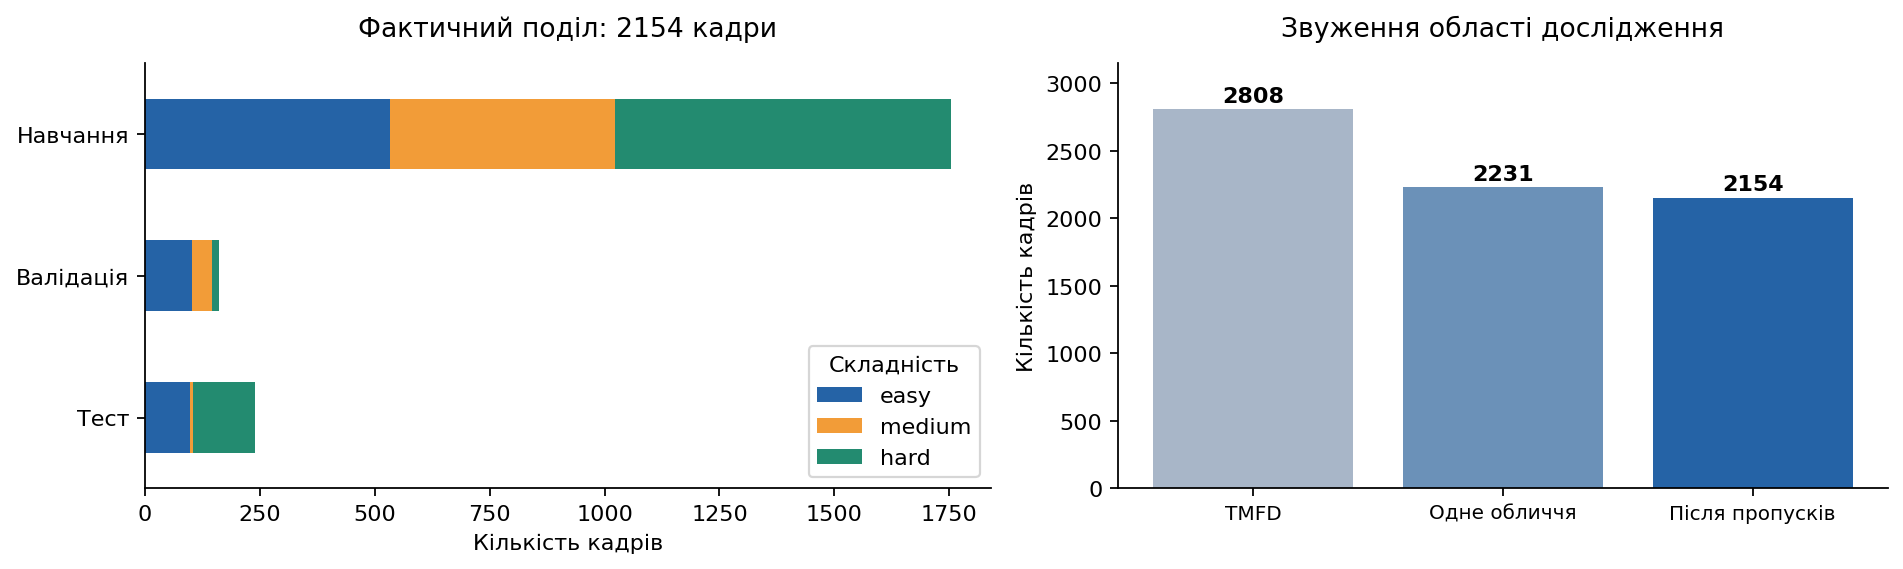

Вхід TMFD: /kaggle/input/datasets/silenceo0/tmfd-dataset-face
Навчений checkpoint: /kaggle/input/notebooks/silenceo0/tmfd-face-spatial-v1/tmfd_spatial_v1/spatial_resnet18.pt


In [7]:
parent = checkpoint_path.parent
rows = []
for name, filename in [("Навчання", "train_ids.csv"), ("Валідація", "validation_ids.csv"), ("Тест", "test_ids.csv")]:
    data = pd.read_csv(parent/filename)
    row = {"Вибірка": name, "Кадрів": len(data)}
    row.update({scene: int((data.scene == scene).sum()) for scene in ["easy", "medium", "hard"]})
    rows.append(row)
frame = pd.DataFrame(rows).set_index("Вибірка")
assert frame["Кадрів"].tolist() == [1753, 162, 239], "Attached checkpoint split changed"
display(frame)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.7), gridspec_kw={"width_ratios": [1.1, 1]})
frame[["easy", "medium", "hard"]].plot.barh(stacked=True, color=COLORS, ax=axes[0], rot=0)
axes[0].set(xlabel="Кількість кадрів", ylabel="", title="Фактичний поділ: 2154 кадри")
axes[0].legend(title="Складність", loc="lower right")
axes[0].invert_yaxis()
axes[1].bar(["TMFD", "Одне обличчя", "Після пропусків"], [2808, 2231, 2154], color=["#a8b6c8", "#6b91b8", "#2563a6"])
axes[1].set(title="Звуження області дослідження", ylabel="Кількість кадрів", ylim=(0, 3150))
for index, count in enumerate([2808, 2231, 2154]):
    axes[1].text(index, count+55, str(count), ha="center", fontweight="bold")
axes[1].tick_params(axis="x", labelsize=9)
fig.tight_layout()
fig.savefig(OUT / 'dataset_split_uk.png', dpi=160, bbox_inches="tight")
plt.close(fig)
display(Image(filename=str(OUT / 'dataset_split_uk.png')))
print("Вхід TMFD:", archive_path)
print("Навчений checkpoint:", checkpoint_path)
split_table = frame


### Якість карти глибини

Перевіряємо невалідні значення depth і показуємо рамки розмітки.

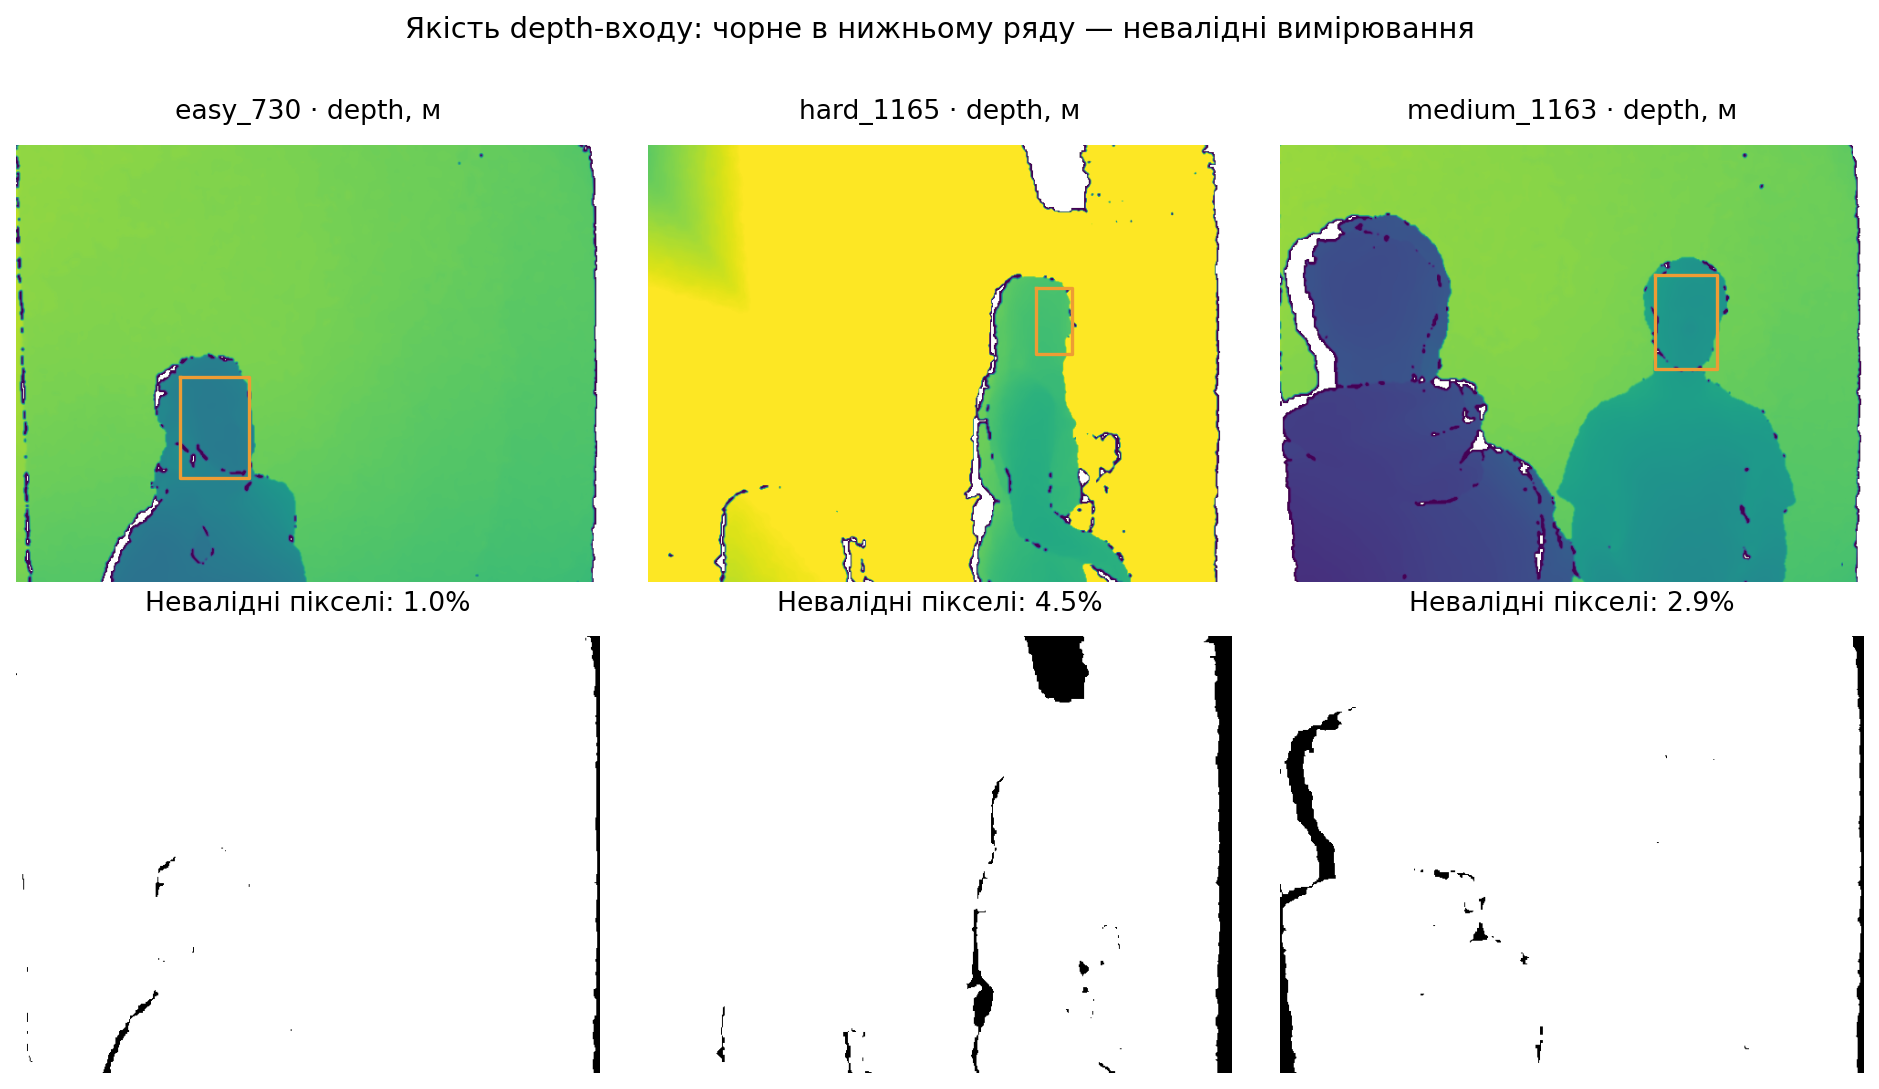

,"Кадр: середнє, %","Кадр: максимум, %","ROI обличчя: середнє, %","ROI обличчя: максимум, %"
scene,,,,
easy,1.24,5.23,1.23,10.14
hard,6.08,9.61,0.32,4.47
medium,4.70,11.93,9.67,25.68


In [8]:
archive, prefix = open_tmfd_dataset(archive_path)
rows = []
selected = np.linspace(0, len(test_ids)-1, 3, dtype=int)
examples = {}
for index, identifier in enumerate(test_ids):
    raw, box = read_tmfd_raw(archive, prefix, identifier)
    invalid = ~np.isfinite(raw) | (raw <= 0) | (raw >= 65535)
    x1, y1 = np.maximum(np.rint((box[:2]-box[3:5]/2)*[640, 480]).astype(int), 0)
    x2, y2 = np.minimum(np.rint((box[:2]+box[3:5]/2)*[640, 480]).astype(int), [640, 480])
    roi = invalid[y1:y2, x1:x2]
    rows.append({"id": identifier, "scene": identifier.rsplit("_", 1)[0], "invalid_frame_fraction": float(invalid.mean()),
        "invalid_reference_roi_fraction": float(roi.mean()) if roi.size else np.nan})
    if index in selected:
        examples[index] = (identifier, raw, invalid, (x1, y1, x2, y2))
archive.close()
audit = pd.DataFrame(rows)
audit.to_csv(OUT/"depth_quality_audit.csv", index=False)
fig, axes = plt.subplots(2, 3, figsize=(12, 6.9))
for column, index in enumerate(selected):
    identifier, raw, invalid, (x1, y1, x2, y2) = examples[index]
    valid = np.ma.masked_where(invalid, raw*.001)
    axes[0, column].imshow(valid, cmap="viridis", vmin=.3, vmax=2)
    axes[0, column].plot([x1,x2,x2,x1,x1], [y1,y1,y2,y2,y1], color="#ee9c34", lw=1.5)
    axes[0, column].set_title(identifier+" · depth, м")
    axes[1, column].imshow(invalid, cmap="gray_r", vmin=0, vmax=1)
    axes[1, column].set_title(f"Невалідні пікселі: {invalid.mean():.1%}")
    for row in range(2): axes[row, column].axis("off")
fig.suptitle("Якість depth-входу: чорне в нижньому ряду — невалідні вимірювання", fontsize=13)
fig.tight_layout(rect=[0,0,1,.95], h_pad=2.8)
fig.savefig(OUT / 'depth_quality_uk.png', dpi=160, bbox_inches="tight")
plt.close(fig)
display(Image(filename=str(OUT / 'depth_quality_uk.png')))
summary = audit.groupby("scene")[["invalid_frame_fraction", "invalid_reference_roi_fraction"]].agg(["mean", "max"])*100
summary.columns = ["Кадр: середнє, %", "Кадр: максимум, %", "ROI обличчя: середнє, %", "ROI обличчя: максимум, %"]
display(summary.round(2))
depth_audit = audit


<a id="model"></a>
## 2. Архітектура та навчання

Показуємо архітектуру моделі й історію вже виконаного навчання.
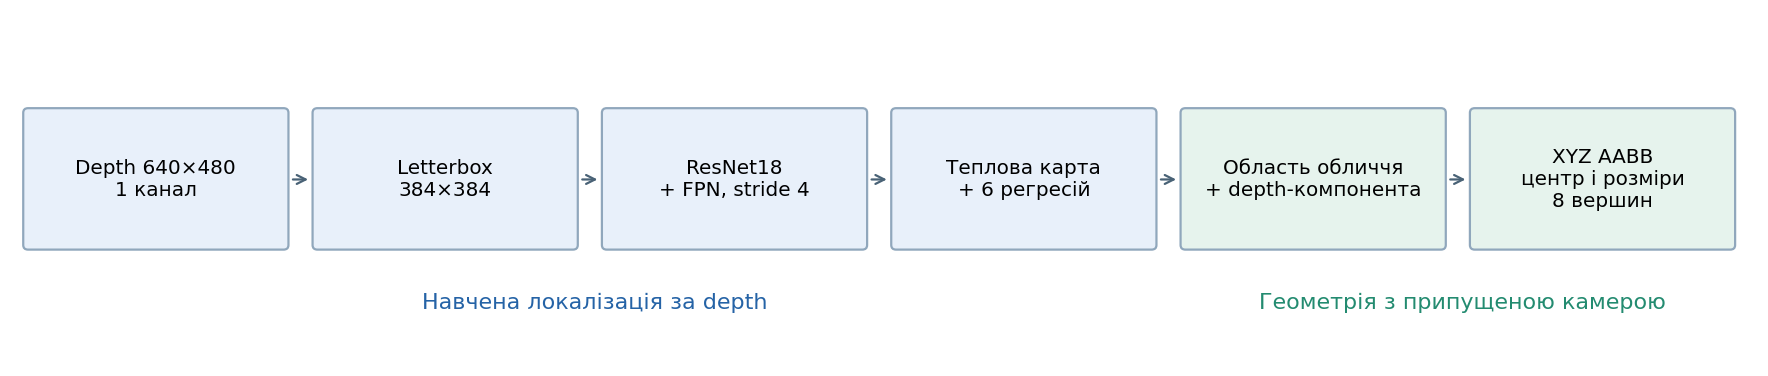


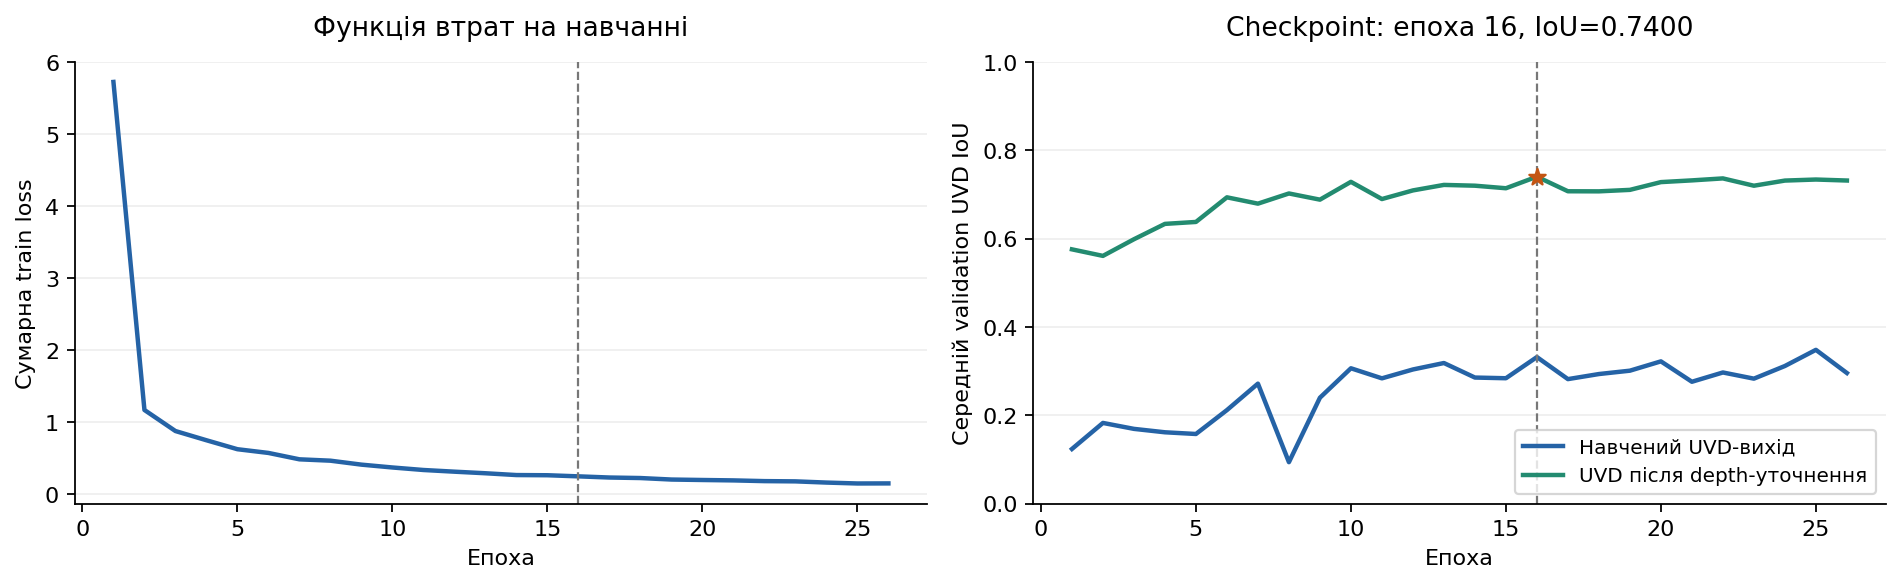

,Параметр,Значення
0,Завершено епох,26
1,Обрана епоха,16
2,Validation UVD IoU,0.74
3,Режим depth,refined


In [9]:
history = pd.read_csv(checkpoint_path.parent/"history.csv")
selection = json.loads((checkpoint_path.parent/"selection.json").read_text(encoding="utf-8"))
selected = int(selection["epoch"])
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].plot(history.epoch, history.train_loss, color=COLORS[0], lw=2)
axes[0].set(xlabel="Епоха", ylabel="Сумарна train loss", title="Функція втрат на навчанні")
axes[1].plot(history.epoch, history.validation_IoU_learned, label="Навчений UVD-вихід", color=COLORS[0], lw=2)
axes[1].plot(history.epoch, history.validation_IoU_refined, label="UVD після depth-уточнення", color=COLORS[2], lw=2)
axes[1].scatter([selected], [selection["validation_IoU"]], s=60, marker="*", zorder=3, color="#c45513")
axes[1].set(xlabel="Епоха", ylabel="Середній validation UVD IoU", title=f"Checkpoint: епоха {selected}, IoU={selection['validation_IoU']:.4f}", ylim=(0, 1))
axes[1].legend(fontsize=9, loc="lower right")
for ax in axes:
    ax.axvline(selected, color="#777", linestyle="--", lw=1)
    ax.grid(axis="y")
fig.tight_layout()
fig.savefig(OUT / 'training_history_uk.png', dpi=160, bbox_inches="tight")
plt.close(fig)
display(Image(filename=str(OUT / 'training_history_uk.png')))
display(pd.DataFrame({"Параметр": ["Завершено епох", "Обрана епоха", "Validation UVD IoU", "Режим depth"],
    "Значення": [len(history), selected, round(selection["validation_IoU"], 4), selection["depth_mode"]]}))


<a id="camera"></a>
## 3. Параметри камери

Параметри камери припускаємо за номінальним полем зору 60° × 49,5° і масштабом depth 0,001 м на одиницю ([джерело, таблиця 1](https://doi.org/10.1145/3523111.3523116)); фактичне калібрування оброблених кадрів TMFD невідоме. У системі камери X спрямована праворуч, Y — вниз, Z — вперед, тому отримані метричні координати залежать від цих припущень.


In [10]:
camera_table = pd.DataFrame({"Параметр": ["W × H", "fx / fy, px", "cx / cy, px", "Depth scale, м", "Статус"],
    "Значення": ["640 × 480", f"{CAMERA_CONFIG['fx']:.3f} / {CAMERA_CONFIG['fy']:.3f}", "319.5 / 239.5", "0.001", CAMERA_CONFIG["calibration_status"]]})
display(camera_table)


,Параметр,Значення
0,W × H,640 × 480
1,"fx / fy, px",554.256 / 520.600
2,"cx / cy, px",319.5 / 239.5
3,"Depth scale, м",0.001
4,Статус,assumed_nominal_fov_not_measured


<a id="evaluation"></a>
## 4. Оцінювання

Виконуємо прогнозування на тестових кадрах і зберігаємо метрики та XYZ-бокси.

In [11]:
with contextlib.redirect_stdout(io.StringIO()) as evaluation_log:
    metrics = evaluate_xyz(archive_path, checkpoint_path, camera_path, test_ids, OUT)
(OUT/"evaluation_runtime.log").write_text(evaluation_log.getvalue(), encoding="utf-8")
print("Оцінено тестових кадрів:", len(test_ids))


Оцінено тестових кадрів: 239


### Результати 3D-локалізації

Показуємо якість побудови XYZ-боксів навченою моделлю та результати за сценами.


In [12]:
if len(metrics) != 1:
    raise ValueError("Expected one trained spatial model")
metric = metrics[0]
rows = [
    ("Тестових кадрів", str(metric["n_test"])),
    ("Валідних XYZ-прогнозів", str(round(metric["valid_prediction_fraction"] * metric["n_test"]))),
    ("Середній XYZ IoU", f'{metric["IoU_XYZ_assumed_mean"]:.4f}'),
    ("IoU ≥ 0.25, %", f'{metric["success_IoU_XYZ_0.25"] * 100:.2f}'),
    ("IoU ≥ 0.50, %", f'{metric["success_IoU_XYZ_0.50"] * 100:.2f}'),
    ("Похибка центра, см", f'{metric["center_error_m_on_valid_pairs"] * 100:.3f}'),
    ("MAE розміру X, см", f'{metric["size_X_MAE_m_on_valid_pairs"] * 100:.3f}'),
    ("MAE розміру Y, см", f'{metric["size_Y_MAE_m_on_valid_pairs"] * 100:.3f}'),
    ("MAE розміру Z, см", f'{metric["size_Z_MAE_m_on_valid_pairs"] * 100:.3f}'),
]
table = pd.DataFrame(rows, columns=["Показник", "Значення"])
display(table)
per_frame = pd.read_csv(OUT / "SpatialResNet18_384_plus_XYZ_geometry_per_frame.csv")
per_frame["scene"] = per_frame.id.str.rsplit("_", n=1).str[0]
per_frame["success"] = per_frame.IoU_XYZ_assumed >= .5
summary = per_frame.groupby("scene").agg(Кадрів=("id", "size"), XYZ_IoU=("IoU_XYZ_assumed", "mean"), Успіх_05=("success", "mean"))
display(summary.round(4))


,Показник,Значення
0,Тестових кадрів,239
1,Валідних XYZ-прогнозів,239
2,Середній XYZ IoU,0.6003
3,"IoU ≥ 0.25, %",91.63
4,"IoU ≥ 0.50, %",71.13
5,"Похибка центра, см",2.794
6,"MAE розміру X, см",1.489
7,"MAE розміру Y, см",1.781
8,"MAE розміру Z, см",1.196


,Кадрів,XYZ_IoU,Успіх_05
scene,,,
easy,98,0.7081,0.8980
hard,135,0.5253,0.5852
medium,6,0.5283,0.5000


<a id="visuals"></a>
## 5. Візуалізація 3D-боксів

Показуємо просторові бокси, їхні центри, розміри та вісім вершин.

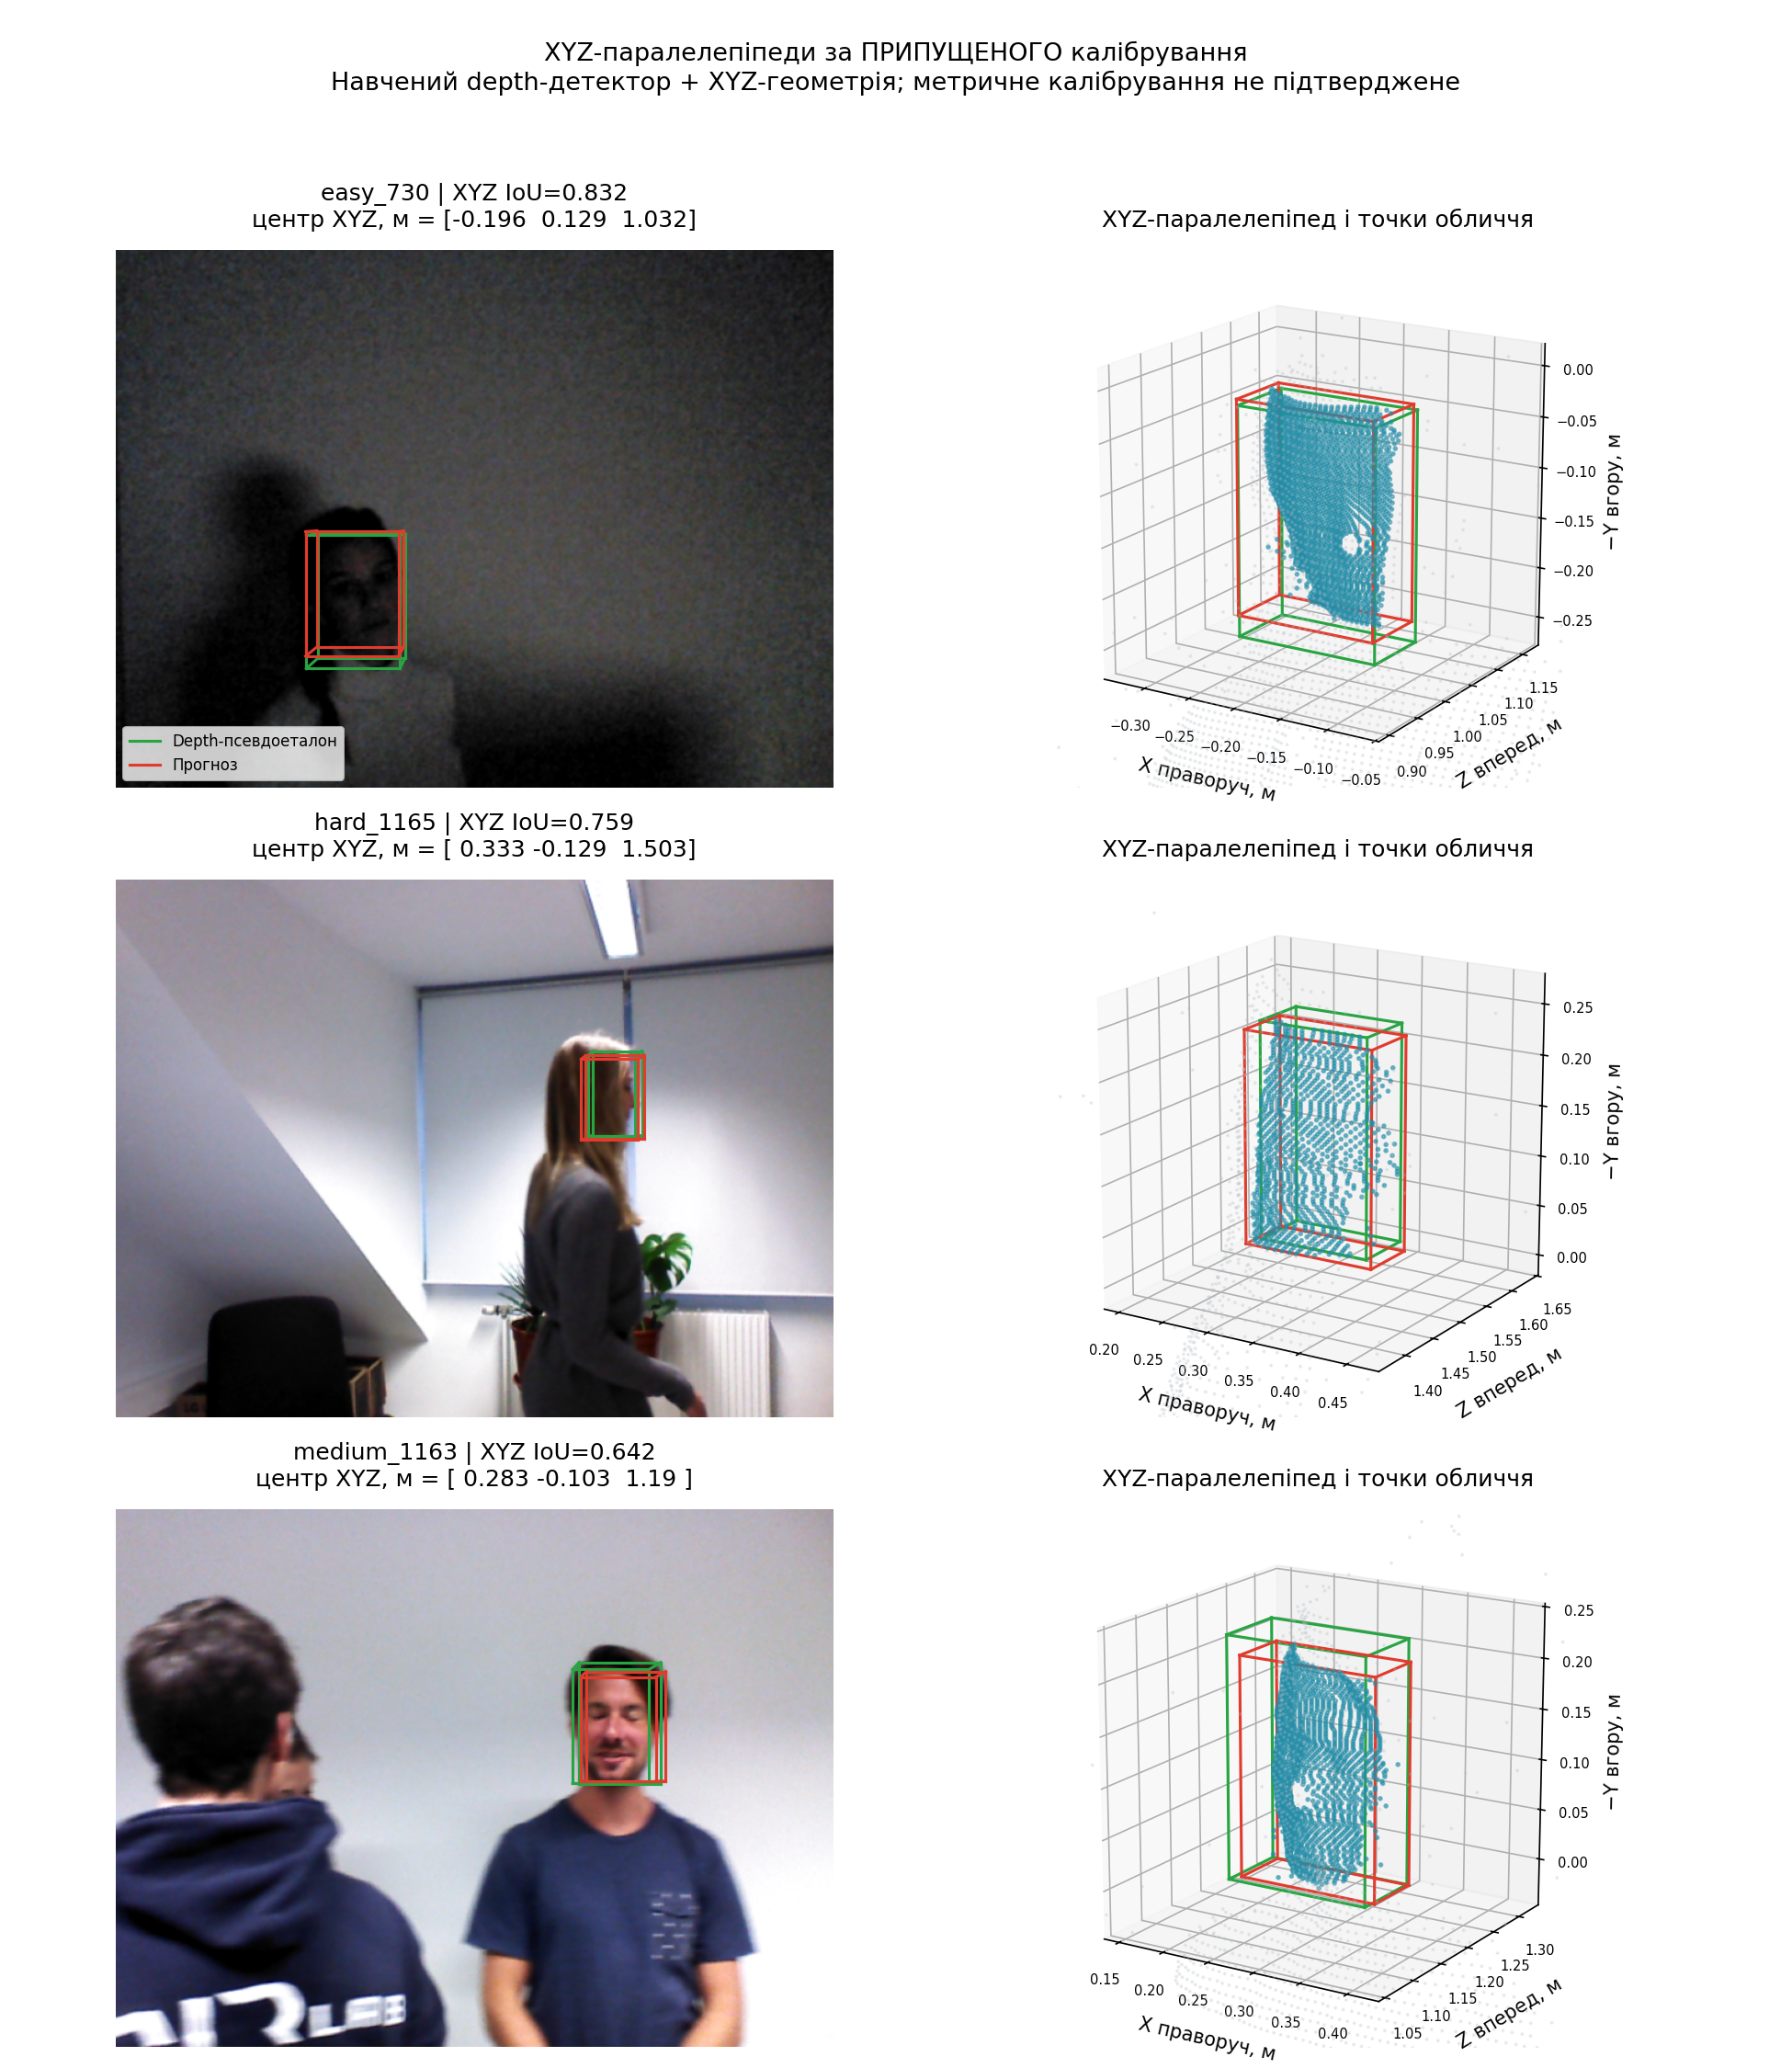

,"Центр XYZ, м","Розміри XYZ, м"
X,-0.1963,0.1489
Y,0.1286,0.2126
Z,1.0320,0.0720


,"X, м","Y, м","Z, м"
Вершина,,,
0,-0.2707,0.0223,0.996
1,-0.2707,0.0223,1.068
2,-0.2707,0.2349,0.996
3,-0.2707,0.2349,1.068
4,-0.1218,0.0223,0.996
5,-0.1218,0.0223,1.068
6,-0.1218,0.2349,0.996
7,-0.1218,0.2349,1.068


In [13]:
display(Image(filename=str(OUT/"xyz_cuboids.png")))
example = json.loads((OUT/"example_prediction.json").read_text(encoding="utf-8"))
display(pd.DataFrame({"Центр XYZ, м": example["center_xyz_m"], "Розміри XYZ, м": example["size_xyz_m"]}, index=["X", "Y", "Z"]).round(4))
display(pd.DataFrame(example["corners_xyz_m"], columns=["X, м", "Y, м", "Z, м"]).rename_axis("Вершина").round(4))


<a id="sensitivity"></a>
## 6. Чутливість до параметрів камери

Перевіряємо вплив припущеного поля зору на розміри боксу.

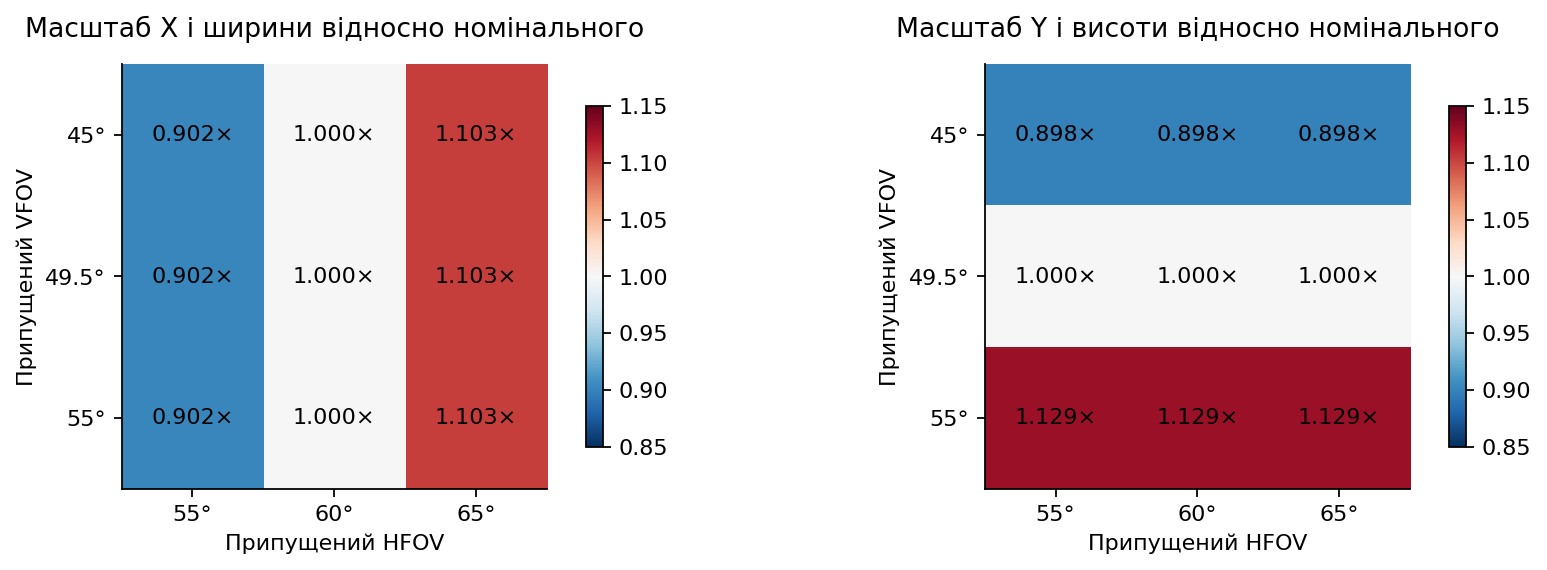

,hfov_assumed_deg,vfov_assumed_deg,mean_width_m,mean_height_m,mean_depth_extent_m
0,55.0,45.0,0.1239,0.1892,0.0893
1,55.0,49.5,0.1239,0.2106,0.0893
2,55.0,55.0,0.1239,0.2378,0.0893
3,60.0,45.0,0.1374,0.1892,0.0893
4,60.0,49.5,0.1374,0.2106,0.0893
5,60.0,55.0,0.1374,0.2378,0.0893
6,65.0,45.0,0.1516,0.1892,0.0893
7,65.0,49.5,0.1516,0.2106,0.0893
8,65.0,55.0,0.1516,0.2378,0.0893


In [14]:
data = pd.read_csv(OUT/"calibration_sensitivity.csv")
fig, axes = plt.subplots(1, 2, figsize=(11, 3.7))
for ax, key, title in [(axes[0], "X_and_width_ratio_to_nominal", "Масштаб X і ширини відносно номінального"),
                       (axes[1], "Y_and_height_ratio_to_nominal", "Масштаб Y і висоти відносно номінального")]:
    pivot = data.pivot(index="vfov_assumed_deg", columns="hfov_assumed_deg", values=key)
    im = ax.imshow(pivot, cmap="RdBu_r", vmin=.85, vmax=1.15)
    ax.set_xticks(range(len(pivot.columns)), [f"{v:g}°" for v in pivot.columns])
    ax.set_yticks(range(len(pivot.index)), [f"{v:g}°" for v in pivot.index])
    ax.set(xlabel="Припущений HFOV", ylabel="Припущений VFOV", title=title)
    for row in range(len(pivot.index)):
        for column in range(len(pivot.columns)):
            ax.text(column, row, f"{pivot.iloc[row,column]:.3f}×", ha="center", va="center")
    fig.colorbar(im, ax=ax, shrink=.8)
fig.tight_layout()
fig.savefig(OUT / 'calibration_sensitivity_uk.png', dpi=160, bbox_inches="tight")
plt.close(fig)
display(Image(filename=str(OUT / 'calibration_sensitivity_uk.png')))
display(data[["hfov_assumed_deg", "vfov_assumed_deg", "mean_width_m", "mean_height_m", "mean_depth_extent_m"]].round(4))


<a id="conclusions"></a>
## 7. Збережені результати

Зберігаємо метрики, XYZ-прогнози та приклад 3D-геометрії у JSON і OBJ. Бокс охоплює видиму поверхню обличчя, а оцінювання використовує depth-псевдоеталон із 2D-розмітки за тією самою припущеною камерою.


In [15]:
artifacts = sorted(path.name for path in OUT.iterdir() if path.is_file())
print("Збережено файлів:", len(artifacts))
print("\n".join(artifacts))


Збережено файлів: 15
SpatialResNet18_384_plus_XYZ_geometry_per_frame.csv
SpatialResNet18_384_plus_XYZ_geometry_predictions.npz
calibration_sensitivity.csv
calibration_sensitivity_uk.png
camera_assumed.json
dataset_split_uk.png
depth_quality_audit.csv
depth_quality_uk.png
evaluation_runtime.log
example_cuboid.obj
example_prediction.json
metrics_XYZ_assumed_camera.csv
predictions_xyz.json
training_history_uk.png
xyz_cuboids.png
